In [3]:
import pandas as pd

# Load datasets
co2_df = pd.read_csv('/Users/pragya.sharma/Downloads/co2_emission.csv')  # read the dataset as a csv file
temp_df = pd.read_csv('/Users/pragya.sharma/Downloads/archive/GlobalLandTemperaturesByCountry.csv')  # read the dataset 2 as a csv file
forest_df = pd.read_csv('/Users/pragya.sharma/Downloads/archive-2/forest_area_km.csv')  # read the dataset 3 as a csv file


In [8]:
co2_df.head()




,Entity,Code,Year,Annual CO₂ emissions (tonnes )
0,Afghanistan,AFG,1949,14656.0
1,Afghanistan,AFG,1950,84272.0
2,Afghanistan,AFG,1951,91600.0
3,Afghanistan,AFG,1952,91600.0
4,Afghanistan,AFG,1953,106256.0


In [11]:
pivot_df = co2_df.pivot(index='Entity', columns='Year', values='Annual CO₂ emissions (tonnes )') # changed the rows to become columns
pivot_df # displayed the columns

Year,1751,1752,1753,1754,1755,1756,1757,1758,1759,1760,...,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017
Entity,,,,,,,,,,,,,,,,,,,,,
Afghanistan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.198330e+06,6.760313e+06,8.452224e+06,1.222602e+07,1.074206e+07,1.000041e+07,9.789186e+06,1.010743e+07,1.225791e+07,1.301474e+07
Africa,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.178143e+09,1.188276e+09,1.193784e+09,1.198373e+09,1.233842e+09,1.250644e+09,1.290489e+09,1.289003e+09,1.310656e+09,1.331740e+09
Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,4.371152e+06,4.374816e+06,4.594656e+06,5.235856e+06,4.906096e+06,5.059984e+06,5.712176e+06,5.947724e+06,6.272858e+06,6.379207e+06
Algeria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.090318e+08,1.201859e+08,1.178141e+08,1.198069e+08,1.281100e+08,1.324346e+08,1.431771e+08,1.505925e+08,1.503780e+08,1.505514e+08
Americas (other),0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.226580e+09,2.157619e+09,2.253919e+09,2.294779e+09,2.375406e+09,2.406775e+09,2.443171e+09,2.435554e+09,2.415058e+09,2.398632e+09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Wallis and Futuna Islands,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.198400e+04,2.931200e+04,2.931200e+04,2.564800e+04,2.564800e+04,2.198400e+04,2.198400e+04,2.399058e+04,2.426549e+04,2.590908e+04
World,9350528.0,9354192.0,9354192.0,9357856.0,9361520.0,10006384.0,10010048.0,10013712.0,10017376.0,10017376.0,...,3.187576e+10,3.152314e+10,3.306665e+10,3.435737e+10,3.491929e+10,3.520789e+10,3.550583e+10,3.546275e+10,3.567510e+10,3.615326e+10
Yemen,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.202498e+07,2.424756e+07,2.315186e+07,1.951301e+07,1.823825e+07,2.498041e+07,2.226257e+07,2.038460e+07,1.913542e+07,1.896575e+07


In [74]:
co2_pivot = pivot_df[[1997, 2013]].dropna()

co2_pivot.reset_index(inplace=True)

# Remove any leading/trailing whitespace in column names
co2_df.columns = co2_df.columns.str.strip()
co2_df.columns = co2_df.columns.astype(str) 


# Rename correctly and reassign it
co2_pivot = co2_pivot.rename(columns={'Entity': 'Country'})
co2_pivot['CO2_Delta'] = co2_pivot[2013] - co2_pivot[1997]


In [75]:
print(co2_pivot.columns.tolist())

['Country', 1997, 2013, 'CO2_Delta']


In [67]:
temp_df['dt'] = pd.to_datetime(temp_df['dt'])

temp_1997 = temp_df[temp_df['dt'] == '1997-01-01'][['Country', 'AverageTemperature']]
temp_2013 = temp_df[temp_df['dt'] == '2013-01-01'][['Country', 'AverageTemperature']]

temp_1997 = temp_1997.rename(columns={'AverageTemperature': 'Temp_1997'})
temp_2013 = temp_2013.rename(columns={'AverageTemperature': 'Temp_2013'})

temp_merged = pd.merge(temp_1997, temp_2013, on='Country')
temp_merged['Temp_Delta'] = temp_merged['Temp_2013'] - temp_merged['Temp_1997']


In [68]:
forest_df = forest_df[['Country', '1993', '2013']].dropna()
forest_df['Forest_Delta'] = forest_df['2013'] - forest_df['1993']
forest_df['Forest_Change_Class'] = forest_df['Forest_Delta'].apply(
    lambda x: 'Loss' if x < -500 else 'Gain' if x > 500 else 'Stable')



In [76]:
final_df = co2_pivot.merge(temp_merged, on='Country').merge(forest_df, on='Country')


In [77]:
final_df.to_csv("merged_environmental_data.csv", index=False)
final_df.head()
final_df

,Country,1997,2013,CO2_Delta,Temp_1997,Temp_2013,Temp_Delta,1993,2013,Forest_Delta,Forest_Change_Class
0,Afghanistan,1.084474e+06,1.000041e+07,8.915940e+06,2.690,2.241,-0.449,12084.400,12084.400,0.000,Stable
1,Albania,1.542544e+06,5.059984e+06,3.517440e+06,5.583,4.412,-1.171,7829.500,7863.405,33.905,Stable
2,Algeria,8.700435e+07,1.324346e+08,4.543028e+07,14.117,12.781,-1.336,16406.000,19408.000,3002.000,Gain
3,Andorra,4.653280e+05,4.763200e+05,1.099200e+04,4.931,4.757,-0.174,160.000,160.000,0.000,Stable
4,Angola,7.347849e+06,3.237311e+07,2.502527e+07,22.321,24.330,2.009,787965.290,704928.140,-83037.150,Loss
...,...,...,...,...,...,...,...,...,...,...,...
145,United States,5.703891e+09,5.519613e+09,-1.842782e+08,-4.012,-2.155,1.857,3027758.000,3095450.000,67692.000,Gain
146,Uruguay,5.513136e+06,7.489844e+06,1.976708e+06,25.833,23.521,-2.312,9693.000,18445.200,8752.200,Gain
147,Uzbekistan,1.070033e+08,1.026549e+08,-4.348449e+06,-0.102,0.346,0.448,26729.974,34694.800,7964.826,Gain
148,Zambia,2.353691e+06,3.756145e+06,1.402454e+06,22.407,23.072,0.665,473046.000,461314.600,-11731.400,Loss


In [78]:
import matplotlib.pyplot as plt
%pip install seaborn
import seaborn as sns





215944.65s - pydevd: Sending message related to process being replaced timed-out after 5 seconds



[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [79]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# Define your features and target
X = final_df[['CO2_Delta', 'Temp_Delta']]
y = final_df['Forest_Change_Class']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Train the Random Forest
rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train, y_train)


RandomForestClassifier(max_depth=5, random_state=42)

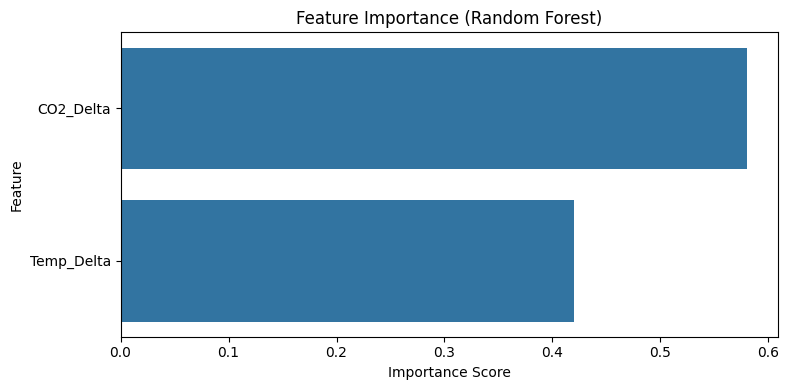

In [80]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
sns.barplot(x=rf.feature_importances_, y=X.columns)
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [55]:
print(final_df.columns.tolist())


['Country', 'Code', 'Year', 'Annual CO₂ emissions (tonnes )', 'Temp_1997', 'Temp_2013', 'Temp_Delta', '1993', '2013', 'Forest_Delta', 'Forest_Change_Class']
